# Спутниктік суреттерден су аумақтарын сегментациялау
**Орындаған — Серикпаева Аружан. Деректер — Sen1Floods11 v1.1.**

Бұл ноутбук Sentinel-1 VV және VH радиолокациялық арналары арқылы әр пиксельдің суға жату ықтималдығын есептейді. Негізгі модель — ImageNet салмақтарынан оқытылған ResNet-34 энкодері бар Attention U-Net.

Қорғау кезінде `Kernel → Restart Kernel and Run All Cells` пәрменін орындаңыз. Әдепкі режим дайын модельді жүктеп, жинақтағы екі Боливия суретіне жаңа болжам жасайды. Толық деректерді алу және GPU-да қайта оқыту төмендегі ауыстырғыштармен қосылады. Толық тесттің сақталған нәтижесі мен осы іске қосуда есептелген демонстрация метрикалары өз атауларымен көрсетіледі.

**Мазмұны**
1. Орта және жұмыс параметрлері
2. Деректердің құрамы және ресми бөлінуі
3. Деректер сапасы, сыныптар теңгерімі және нормализация
4. Архитектура, шығын функциясы және оқыту
5. Оқыту қисықтары және валидациялық шек
6. Базалық әдістермен салыстыру
7. Дайын модельдің болжамдары және қателері
8. Joblib экспорты және қайта жүктеуді тексеру

Су маскасына тұрақты өзен-көлдер де кіреді. Жаңадан су басқан аумақты бөлу үшін тасқынға дейінгі сурет немесе тұрақты су картасы қосымша қажет.

## 1. Орта және жұмыс параметрлері
Python 3.11 және жобаға тіркелген `requirements.txt` қолданылады. Алғаш іске қосқанда терминалда `python -m pip install -r requirements.txt` орындаңыз. Colab-та архивті `/content` ішіне ашып, ноутбукті сол бумадан іске қосуға болады. Дайын модельмен болжау CPU-да да орындалады.

`RUN_FULL_DATA` — барлық 446 фрагментті алу және аудит жасау. `RUN_TRAINING` — толық дерекпен жаңа GPU тәжірибесін орындау. `RUN_FULL_TEST` — дайын модельді ресми 90 тест суреті және 15 Боливия суреті бойынша қайта бағалау. Бұл ауыстырғыштардың әдепкі мәні `False`.

In [1]:
from pathlib import Path
import json
import hashlib
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import joblib
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "models").exists() and (ROOT / "FloodSegmentation_Defense").exists():
    ROOT = ROOT / "FloodSegmentation_Defense"
DATA_DIR = ROOT / "data"
REPORT_DIR = ROOT / "reports"
OUTPUT_DIR = ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_FILE = ROOT / "models" / "attention_unet_resnet34.joblib"
RUN_FULL_DATA = False
RUN_TRAINING = False
RUN_FULL_TEST = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(4, torch.get_num_threads()))
print("Құрылғы:", DEVICE)
print("PyTorch:", torch.__version__)
print("Жоба бумасы:", ROOT)

Құрылғы: cpu
PyTorch: 2.6.0+cpu
Жоба бумасы: .../FloodSegmentation_Defense


## 2. Sen1Floods11 деректері және ресми бөлінуі
Деректер көзі — [Cloud to Street / Sen1Floods11](https://github.com/cloudtostreet/Sen1Floods11). Әр растрдың өлшемі 512 × 512. Екі кіріс арнасы — VV және VH, өлшем бірлігі — dB. Эталон маскада 0 — құрлық, 1 — су, −1 — белгісіз пиксель.

Train — 252, validation — 89, test — 90, Bolivia — 15 фрагмент. Боливия географиялық тұрғыдан бөлек тексеріледі. Патчтар деректер ресми бөлінгеннен кейін жасалады. Тест гиперпараметрлерді немесе шекті таңдауға қатыспайды.

Төмендегі функциялар ресми CSV файлдарынан тізім құрады және қажет болған жағдайда GeoTIFF суреттерін жүктейді.

In [2]:
import json
from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F


def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    def clean(x):
        if isinstance(x, dict):
            return {str(k): clean(v) for k, v in x.items()}
        if isinstance(x, (tuple, list)):
            return [clean(v) for v in x]
        if isinstance(x, np.generic):
            return clean(x.item())
        if isinstance(x, float) and (not np.isfinite(x)):
            return None
        return x

    path.write_text(
        json.dumps(clean(value), indent=2, ensure_ascii=False), encoding="utf-8"
    )


def validate_splits(rows):
    seen = set()
    for r in rows:
        if r["chip_id"] in seen:
            raise ValueError("Duplicate/leaking chip: " + r["chip_id"])
        seen.add(r["chip_id"])
        if (r["event"] == "Bolivia") != (r["split"] == "bolivia"):
            raise ValueError("Bolivia holdout leakage")

In [3]:
import csv, hashlib, io, json, time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import rasterio
from rasterio.windows import Window
import torch
from torch.utils.data import Dataset

BASE = "https://storage.googleapis.com/sen1floods11/v1.1/"
HAND = "data/flood_events/HandLabeled/"


def download(url, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists() and path.stat().st_size:
        try:
            if path.suffix == ".tif":
                with rasterio.open(path) as ds:
                    ds.read()
            return
        except rasterio.errors.RasterioError:
            pass
    temp = path.with_suffix(path.suffix + ".part")
    for attempt in range(3):
        try:
            with requests.get(url, stream=True, timeout=(20, 120)) as r:
                r.raise_for_status()
                with temp.open("wb") as f:
                    for chunk in r.iter_content(1024 * 1024):
                        f.write(chunk)
            temp.replace(path)
            return
        except requests.RequestException:
            if attempt == 2:
                raise
            time.sleep(attempt + 1)


def prepare(root, include_jrc=True, limit=None):
    root = Path(root)
    rows = []
    jobs = []
    for split, remote in [
        ("train", "train"),
        ("valid", "valid"),
        ("test", "test"),
        ("bolivia", "bolivia"),
    ]:
        p = root / "splits" / f"flood_{remote}_data.csv"
        download(BASE + "splits/flood_handlabeled/" + p.name, p)
        pairs = [r for r in csv.reader(io.StringIO(p.read_text())) if r]
        if limit is not None:
            pairs = pairs[:limit]
        for image, label in pairs:
            chip = image.removesuffix("_S1Hand.tif")
            row = dict(chip_id=chip, event=chip.split("_")[0], split=split)
            for key, folder, name in [
                ("image", "S1Hand", image),
                ("label", "LabelHand", label),
            ] + (
                [("jrc", "JRCWaterHand", chip + "_JRCWaterHand.tif")]
                if include_jrc
                else []
            ):
                dest = root / folder / name
                row[key] = str(dest.resolve())
                jobs.append((BASE + HAND + folder + "/" + name, dest))
            rows.append(row)
    validate_splits(rows)
    with ThreadPoolExecutor(max_workers=6) as pool:
        for i, _ in enumerate(pool.map(lambda a: download(*a), jobs), 1):
            if i % 100 == 0 or i == len(jobs):
                print(f"Downloaded/verified {i}/{len(jobs)}", flush=True)
    df = pd.DataFrame(rows)
    df.to_csv(root / "manifest.csv", index=False)
    return df


def read_image(row, window=None):
    with rasterio.open(row["image"]) as ds:
        x = ds.read(window=window).astype("float32")
        iv = (ds.read_masks(window=window) > 0).all(0)
    return (x, iv & np.isfinite(x).all(0))


def read_pair(row, window=None):
    x, iv = read_image(row, window)
    with rasterio.open(row["label"]) as ds:
        y = ds.read(1, window=window)
        lv = ds.read_masks(1, window=window) > 0
    valid = iv & lv & np.isfinite(x).all(0) & np.isin(y, [0, 1])
    return (x, (y == 1).astype("float32"), valid)

In [4]:
rows = []
for split in ["train", "valid", "test", "bolivia"]:
    split_path = DATA_DIR / "splits" / f"flood_{split}_data.csv"
    download(BASE + "splits/flood_handlabeled/" + split_path.name, split_path)
    with split_path.open() as stream:
        for image_name, label_name in csv.reader(stream):
            chip_id = image_name.removesuffix("_S1Hand.tif")
            rows.append(
                {
                    "chip_id": chip_id,
                    "event": chip_id.split("_")[0],
                    "split": split,
                    "image": str(DATA_DIR / "S1Hand" / image_name),
                    "label": str(DATA_DIR / "LabelHand" / label_name),
                }
            )
manifest = pd.DataFrame(rows)
validate_splits(rows)
expected_counts = {"train": 252, "valid": 89, "test": 90, "bolivia": 15}
assert manifest.groupby("split").size().to_dict() == expected_counts
manifest.to_csv(OUTPUT_DIR / "manifest.csv", index=False)
display(manifest.groupby(["split", "event"]).size().unstack(fill_value=0))
print("Бөлінулерде қайталанатын идентификатор жоқ.")

event,Bolivia,Ghana,India,Mekong,Nigeria,Pakistan,Paraguay,Somalia,Spain,Sri-Lanka,USA
split,,,,,,,,,,,
bolivia,15,0,0,0,0,0,0,0,0,0,0
test,0,11,14,6,4,6,14,6,6,9,14
train,0,31,40,18,10,16,39,15,18,24,41
valid,0,11,14,6,4,6,14,5,6,9,14


Бөлінулерде қайталанатын идентификатор жоқ.


## 3. Деректер сапасы және алдын ала өңдеу
Кескін мен эталонның CRS, геотрансформациясы, өлшемі және арна саны салыстырылады. NaN, Inf, nodata және −1 белгілері жарамсыз ретінде есептеледі. Олар шығын функциясы мен метрикадан алынып тасталады.

Әр арна `z = (x − mean) / std` формуласымен нормализацияланады. Mean және std бастапқы оқытудың тек train бөлігінен алынған. Дайын модельді қолданғанда сол параметрлер қайта пайдаланылады. Кіріс суреттің жарамсыз пиксельдері нормализациядан кейін нөлге теңестіріледі. Бағалау маскасы болжам жасауға берілмейді.

Төмендегі аудит функциясы толық деректер режимінде сыныптар арақатынасын, файл хэштерін және бөлінулер арасындағы кеңістіктік қиылысуды тексереді.

In [5]:
import csv, hashlib, io, json, time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import rasterio
from rasterio.windows import Window
import torch
from torch.utils.data import Dataset

BASE = "https://storage.googleapis.com/sen1floods11/v1.1/"
HAND = "data/flood_events/HandLabeled/"


def audit(df, out):
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    records = []
    bounds = []
    sums = np.zeros(2)
    squares = np.zeros(2)
    n = 0
    for row in df.to_dict("records"):
        with rasterio.open(row["image"]) as a, rasterio.open(row["label"]) as b:
            if (
                a.count != 2
                or a.shape != (512, 512)
                or b.count != 1
                or (a.shape != b.shape)
                or (a.crs != b.crs)
                or (not a.transform.almost_equals(b.transform))
            ):
                raise ValueError("Raster geometry mismatch: " + row["chip_id"])
            values = np.unique(b.read(1))
            if not set(values).issubset({-1, 0, 1}):
                raise ValueError(f"Unexpected labels: {values}")
            bounds.append((row["chip_id"], row["split"], str(a.crs), a.bounds))
        x, y, v = read_pair(row)
        rec = {k: row[k] for k in ["chip_id", "event", "split"]}
        rec.update(
            valid_pixels=int(v.sum()),
            water_pixels=int(y[v].sum()),
            invalid_fraction=float(1 - v.mean()),
        )
        for key in ["image", "label"]:
            p = Path(row[key])
            rec[key + "_bytes"] = p.stat().st_size
            rec[key + "_sha256"] = hashlib.sha256(p.read_bytes()).hexdigest()
        records.append(rec)
        if row["split"] == "train":
            _, image_valid = read_image(row)
            z = x[:, image_valid].astype("float64")
            sums += z.sum(1)
            squares += (z * z).sum(1)
            n += z.shape[1]
    overlaps = []
    for i, (aid, asp, crs, a) in enumerate(bounds):
        for bid, bsp, bcrs, b in bounds[i + 1 :]:
            if (
                asp != bsp
                and crs == bcrs
                and (min(a.right, b.right) - max(a.left, b.left) > 1e-08)
                and (min(a.top, b.top) - max(a.bottom, b.bottom) > 1e-08)
            ):
                overlaps.append([aid, bid])
    write_json(out / "spatial_overlaps.json", overlaps)
    if overlaps:
        raise ValueError(
            "Spatial overlap between splits; inspect report before training"
        )
    if not n:
        raise ValueError("No valid training pixels")
    mean = sums / n
    std = np.sqrt(np.maximum(squares / n - mean**2, 1e-12))
    norm = {
        "mean": mean.tolist(),
        "std": std.tolist(),
        "train_valid_pixels": n,
        "units": "dB",
    }
    write_json(out / "normalization.json", norm)
    stats = pd.DataFrame(records)
    stats.to_csv(out / "audit.csv", index=False)
    stats.groupby(["split", "event"]).agg(
        tiles=("chip_id", "count"),
        valid_pixels=("valid_pixels", "sum"),
        water_pixels=("water_pixels", "sum"),
    ).to_csv(out / "split_summary.csv")
    return (norm, stats)


def normalize(x, valid, norm):
    z = (x - np.asarray(norm["mean"], dtype="float32")[:, None, None]) / np.asarray(
        norm["std"], dtype="float32"
    )[:, None, None]
    z[:, ~valid] = 0
    return z


class FloodDataset(Dataset):

    def __init__(self, df, split, norm, augment=False):
        self.rows = df[df.split == split].to_dict("records")
        self.norm = norm
        self.augment = augment
        self.items = []
        self.skipped = 0
        for i, r in enumerate(self.rows):
            _, _, v = read_pair(r)
            for top in [0, 256]:
                for left in [0, 256]:
                    if v[top : top + 256, left : left + 256].any():
                        self.items.append((i, top, left))
                    else:
                        self.skipped += 1

    def __len__(self):
        return len(self.items)

    def __getitem__(self, k):
        i, top, left = self.items[k]
        row = self.rows[i]
        window = Window(left, top, 256, 256)
        x, y, v = read_pair(row, window)
        _, image_valid = read_image(row, window)
        x = normalize(x, image_valid, self.norm)
        y = y[None]
        v = v[None]
        if self.augment:
            turns = int(torch.randint(4, ()).item())
            flip = bool(torch.rand(()) < 0.5)
            arrays = [np.rot90(a, turns, axes=(-2, -1)) for a in [x, y, v]]
            x, y, v = [np.flip(a, -1) if flip else a for a in arrays]
        return {
            "image": torch.from_numpy(x.copy()),
            "target": torch.from_numpy(y.copy()),
            "valid": torch.from_numpy(v.copy()),
            "chip_id": row["chip_id"],
            "top": top,
            "left": left,
        }

In [6]:
if RUN_FULL_DATA or RUN_TRAINING:
    manifest = prepare(DATA_DIR, include_jrc=False)
    training_normalization, audit_table = audit(manifest, OUTPUT_DIR / "full_audit")
    balance = audit_table.groupby("split")[["valid_pixels", "water_pixels"]].sum()
    balance["water_fraction"] = balance.water_pixels / balance.valid_pixels
    display(balance)
else:
    print(
        "Толық аудит коды дайын. Демонстрация үшін жинақтағы екі Боливия суреті қолданылады."
    )

Толық аудит коды дайын. Демонстрация үшін жинақтағы екі Боливия суреті қолданылады.


### 3.1 Сыныптардың арақатынасы
Төмендегі кесте бастапқы оқыту журналы мен сақталған бағалау нәтижелеріндегі TP, FP, FN және TN сандарынан есептеледі. Су пиксельдері — TP + FN, құрлық — TN + FP. Толық тор көлемі мен осы қосындының айырмасы бағалауға кірмеген пиксельдер санын береді. Толық аудит режимінде осы сандар бастапқы GeoTIFF маскаларынан қайта тексеріледі.

In [7]:
saved_history = pd.read_csv(REPORT_DIR / "history.csv")
last_epoch = saved_history.iloc[-1]
saved_main_test = json.loads((REPORT_DIR / "attention_main_test.json").read_text())
saved_bolivia = json.loads((REPORT_DIR / "results.json").read_text())["bolivia"][
    "attention"
]
balance_records = []
for split in ["train", "valid", "test", "bolivia"]:
    if split in ["train", "valid"]:
        pixel_counts = {
            key: int(last_epoch[f"{split}_{key}"]) for key in ["tp", "fp", "fn", "tn"]
        }
    else:
        pixel_counts = saved_main_test if split == "test" else saved_bolivia
    water_pixels = pixel_counts["tp"] + pixel_counts["fn"]
    land_pixels = pixel_counts["tn"] + pixel_counts["fp"]
    total_pixels = expected_counts[split] * 512 * 512
    balance_records.append(
        {
            "Бөлік": split,
            "Фрагмент": expected_counts[split],
            "Су пикселі": water_pixels,
            "Құрлық пикселі": land_pixels,
            "Жарамсыз пиксель": total_pixels - water_pixels - land_pixels,
            "Су үлесі": water_pixels / (water_pixels + land_pixels),
        }
    )
display(pd.DataFrame(balance_records).set_index("Бөлік"))

,Фрагмент,Су пикселі,Құрлық пикселі,Жарамсыз пиксель,Су үлесі
Бөлік,,,,,
train,252,5446678,51570919,9042691,0.095526
valid,89,2231206,18042948,3056662,0.110052
test,90,2515008,17928951,3149001,0.123020
bolivia,15,451901,2372533,1107726,0.159997


## 4. Модель архитектурасы және оқыту
ResNet-34 энкодері белгілерді бірнеше масштабта шығарады. Декодер кеңістіктік өлшемді қалпына келтіреді. Төрт аралық байланыстың әрқайсысында `GatedSkip` блогы декодер контексті мен энкодер белгілерінен назар картасын есептеп, сол картаға энкодер белгілерін көбейтеді.

ImageNet-тен алынған энкодер қабаттары негізгі тәжірибеде толық қайта оқытылды. Кіріс — 2 арна, шығыс — 1 логит картасы. Sigmoid логитті су ықтималдығына түрлендіреді. Төменде кәдімгі U-Net пен ResNet-34 нұсқаларының да құрылысы көрсетілген.

In [8]:
import torch
from torch import nn
import torch.nn.functional as F


def block(a, b):
    return nn.Sequential(
        nn.Conv2d(a, b, 3, padding=1, bias=False),
        nn.BatchNorm2d(b),
        nn.ReLU(inplace=True),
        nn.Conv2d(b, b, 3, padding=1, bias=False),
        nn.BatchNorm2d(b),
        nn.ReLU(inplace=True),
    )


class PlainUNet(nn.Module):

    def __init__(self):
        super().__init__()
        widths = [32, 64, 128, 256, 512]
        self.enc = nn.ModuleList(
            [block(a, b) for a, b in zip([2] + widths[:-1], widths)]
        )
        self.dec = nn.ModuleList(
            [block(a + b, b) for a, b in zip(widths[:0:-1], widths[-2::-1])]
        )
        self.head = nn.Conv2d(32, 1, 1)

    def forward(self, x):
        skips = []
        for i, layer in enumerate(self.enc):
            if i:
                x = F.max_pool2d(x, 2)
            x = layer(x)
            skips.append(x)
        for layer, skip in zip(self.dec, skips[-2::-1]):
            x = layer(
                torch.cat(
                    [
                        F.interpolate(
                            x,
                            size=skip.shape[-2:],
                            mode="bilinear",
                            align_corners=False,
                        ),
                        skip,
                    ],
                    1,
                )
            )
        return self.head(x)


class GatedSkip(nn.Module):
    """Modulate a skip using a decoder-conditioned spatial attention map."""

    def __init__(self, decoder_channels, skip_channels):
        super().__init__()
        self.decoder_channels = decoder_channels
        hidden = max(skip_channels // 2, 1)
        self.decoder_projection = nn.Conv2d(decoder_channels, hidden, 1)
        self.skip_projection = nn.Conv2d(skip_channels, hidden, 1)
        self.score = nn.Conv2d(hidden, 1, 1)

    def forward(self, fused):
        decoder = fused[:, : self.decoder_channels]
        skip = fused[:, self.decoder_channels :]
        score = self.score(
            F.relu(self.decoder_projection(decoder) + self.skip_projection(skip))
        )
        return torch.cat((decoder, skip * score.sigmoid()), dim=1)


def build_model(name="resnet34", pretrained=True):
    if name == "plain":
        return PlainUNet()
    if name not in ("resnet34", "attention_resnet34"):
        raise ValueError(name)
    import segmentation_models_pytorch as smp

    model = smp.Unet(
        encoder_name="resnet34",
        encoder_weights="imagenet" if pretrained else None,
        in_channels=2,
        classes=1,
        activation=None,
    )
    if name == "attention_resnet34":
        skip_widths = reversed(model.encoder.out_channels[1:-1])
        for stage, skip_width in zip(model.decoder.blocks, skip_widths):
            decoder_width = stage.conv1[0].in_channels - skip_width
            stage.attention1 = GatedSkip(decoder_width, skip_width)
    return model

### 4.1 Дайын модельді жүктеу
Joblib пакетінде салмақтар NumPy массивтері ретінде, сонымен бірге архитектура атауы, нормализация, шек, дәуір және деректер идентификаторлары сақталған. Архитектура жоғарыдағы кодпен құрылады, содан кейін оқытылған салмақтар жүктеледі. Пакет тек сенімді жоба көзінен алынуы керек, себебі joblib pickle механизміне сүйенеді.

In [9]:
if not MODEL_FILE.exists():
    checkpoint_candidates = [
        ROOT / "best.pt",
        ROOT / "models" / "best.pt",
        ROOT.parent / "best.pt",
        Path(
            "/content/drive/MyDrive/FloodSegmentation/runs/attention_resnet34_seed42/best.pt"
        ),
    ]
    checkpoint = next((path for path in checkpoint_candidates if path.is_file()), None)
    if checkpoint is None:
        raise FileNotFoundError(
            "Дайын best.pt файлын осы ноутбук тұрған бумаға сақтаңыз. "
            "Содан кейін осы ұяшықты қайта орындаңыз."
        )
    import sys

    if str(ROOT) not in sys.path:
        sys.path.insert(0, str(ROOT))
    from export_checkpoint import export_checkpoint

    export_checkpoint(checkpoint, MODEL_FILE)

bundle = joblib.load(MODEL_FILE)
assert bundle["format_version"] == 1
assert bundle["config"]["model"] == "attention_resnet34"
model = build_model(bundle["config"]["model"], pretrained=False)
model.load_state_dict(
    {
        name: torch.from_numpy(value.copy())
        for name, value in bundle["state_dict"].items()
    },
    strict=True,
)
model = model.to(DEVICE).eval()
normalization = bundle["normalization"]
threshold = float(bundle["threshold"])
for split, expected in bundle["split_ids"].items():
    actual = sorted(manifest.loc[manifest.split == split, "chip_id"])
    assert actual == sorted(expected), f"Бөліну сәйкес емес: {split}"
print("Модель:", bundle["config"]["model"])
print("Таңдалған дәуір:", bundle["epoch"])
print("Шек:", threshold)
print("Параметр саны:", sum(parameter.numel() for parameter in model.parameters()))
display(pd.DataFrame(normalization, index=["VV", "VH"])[["mean", "std"]])

D:\Python 3.11\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Модель: attention_resnet34
Таңдалған дәуір: 34
Шек: 0.473
Параметр саны: 24567125


,mean,std
VV,-10.392862,4.038801
VH,-17.241102,4.753971


### 4.2 Шығын функциясы және метрикалар
`BCEWithLogits + Dice loss` тек эталоны бар пиксельдерде есептеледі. BCE пиксельдік шешімге, Dice су маскасының қабысуына үлес қосады. Бос жарамды маскасы бар патчтар өткізіледі.

IoU = TP / (TP + FP + FN). Dice/F1 = 2TP / (2TP + FP + FN). Precision = TP / (TP + FP). Recall = TP / (TP + FN). Толық жиынтық метрикалары барлық суреттердің TP, FP, FN және TN сандары қосылғаннан кейін есептеледі.

In [10]:
import json
from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F


def counts(pred, target, valid):
    p = np.asarray(pred, dtype=bool)
    y = np.asarray(target, dtype=bool)
    v = np.asarray(valid, dtype=bool)
    return np.array(
        [
            (p & y & v).sum(),
            (p & ~y & v).sum(),
            (~p & y & v).sum(),
            (~p & ~y & v).sum(),
        ],
        dtype=np.int64,
    )


def metrics(c):
    tp, fp, fn, tn = map(int, c)

    def div(a, b):
        return a / b if b else float("nan")

    return dict(
        iou=div(tp, tp + fp + fn),
        f1=div(2 * tp, 2 * tp + fp + fn),
        precision=div(tp, tp + fp),
        recall=div(tp, tp + fn),
        tp=tp,
        fp=fp,
        fn=fn,
        tn=tn,
    )


def masked_loss(logits, target, valid):
    if not valid.any():
        return None
    z = logits[valid].float()
    y = target[valid].float()
    p = z.sigmoid()
    return (
        F.binary_cross_entropy_with_logits(z, y)
        + 1
        - (2 * (p * y).sum() + 1e-06) / (p.sum() + y.sum() + 1e-06)
    )


def assemble(patches, size=512, patch=256):
    if size % patch or len(patches) != (size // patch) ** 2:
        raise ValueError("Incomplete tiling")
    out = np.zeros((size, size), dtype=np.asarray(patches[0]).dtype)
    for k, a in enumerate(patches):
        r, c = divmod(k, size // patch)
        out[r * patch : (r + 1) * patch, c * patch : (c + 1) * patch] = a
    return out

### 4.3 Оқыту циклі
Оқыту патчы — 256 × 256. Train патчтарына 90°-қа еселі бұрылу және көлденең аудару бірдей түрде суретке, эталонға және жарамдылық маскасына қолданылады. Validation аугментациясыз бағаланады.

Оптимизатор — AdamW, learning rate — 0,0001, weight decay — 0,0001, batch size — 8, seed — 42. Ең көп 100 дәуір, early stopping patience — 15. Үздік салмақ валидациялық IoU бойынша сақталады. `last.pt` оқытуды жалғастыруға қажет оптимизатор мен кездейсоқ сандар күйін де сақтайды.

Код төменде ашық берілген. Жаңа оқыту `RUN_TRAINING=True` және GPU болғанда бөлек `retraining` бумасына жазылады. Осы ноутбуктегі негізгі бағалау бұрын оқытылған дайын модельге қатысты.

In [11]:
import json, random, time, platform, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, Subset

DEFAULT = dict(
    model="resnet34",
    pretrained=True,
    seed=42,
    batch_size=8,
    workers=2,
    epochs=100,
    patience=15,
    lr=0.0001,
    weight_decay=0.0001,
)


def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def save_checkpoint(path, state):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix(".tmp")
    torch.save(state, temp)
    temp.replace(path)


def environment(out):
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    import sys

    versions = subprocess.check_output(
        [sys.executable, "-m", "pip", "freeze"], text=True
    )
    (out / "requirements-lock.txt").write_text(versions, encoding="utf-8")
    info = dict(
        python=platform.python_version(),
        torch=torch.__version__,
        cuda=torch.cuda.is_available(),
        gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    )
    write_json(out / "environment.json", info)
    return info


def epoch(model, loader, device, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    total = np.zeros(4, dtype=np.int64)
    losses = []
    for batch in loader:
        x = batch["image"].to(device)
        y = batch["target"].to(device)
        v = batch["valid"].to(device)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training), torch.autocast(
            device_type=device.type, enabled=device.type == "cuda"
        ):
            z = model(x)
            loss = masked_loss(z, y, v)
        if loss is None:
            continue
        if not torch.isfinite(loss):
            raise FloatingPointError("Non-finite loss")
        if training:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        losses.append(float(loss.detach()))
        total += counts(
            z.detach().sigmoid().cpu().numpy() >= 0.5, y.cpu().numpy(), v.cpu().numpy()
        )
    if not losses:
        raise ValueError("Empty valid dataset")
    return {"loss": float(np.mean(losses)), **metrics(total)}


def overfit_check(df, norm, out, steps=80, device=None):
    device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
    seed_all(42)
    dataset = FloodDataset(df, "train", norm, False)
    loader = DataLoader(
        Subset(dataset, list(range(min(4, len(dataset))))), batch_size=2, shuffle=False
    )
    model = build_model("resnet34", False).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")
    history = []
    start = time.time()
    for i in range(steps):
        m = epoch(model, loader, device, optimizer, scaler)
        history.append(m["loss"])
    result = {
        "first_loss": history[0],
        "last_loss": history[-1],
        "seconds": time.time() - start,
        "steps": steps,
    }
    write_json(Path(out) / "overfit_check.json", result)
    if history[-1] >= history[0] * 0.7:
        raise RuntimeError("Tiny-set overfit check failed; inspect data and model")
    del model, optimizer
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return result


def train(df, norm, out, config=None, resume=True, allow_cpu=False):
    cfg = {**DEFAULT, **(config or {})}
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    if not torch.cuda.is_available() and (not allow_cpu):
        raise RuntimeError("Select GPU in Colab; full CPU training is disabled")
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    seed_all(cfg["seed"])
    trainset = FloodDataset(df, "train", norm, True)
    valset = FloodDataset(df, "valid", norm, False)
    generator = torch.Generator().manual_seed(cfg["seed"])
    loader = DataLoader(
        trainset,
        batch_size=cfg["batch_size"],
        shuffle=True,
        num_workers=cfg["workers"],
        generator=generator,
        pin_memory=device.type == "cuda",
    )
    valid = DataLoader(valset, batch_size=cfg["batch_size"], num_workers=cfg["workers"])
    last = out / "last.pt"
    state = None
    if resume and last.exists():
        state = torch.load(last, map_location="cpu", weights_only=False)
        for key in cfg:
            if key not in ["epochs", "workers"] and state["config"][key] != cfg[key]:
                raise ValueError("Resume config mismatch: " + key)
        if state["normalization"] != norm:
            raise ValueError("Resume normalization mismatch")
        old_ids = state["split_ids"]
        ids = {s: sorted(df[df.split == s].chip_id.tolist()) for s in df.split.unique()}
        if old_ids != ids:
            raise ValueError("Resume dataset mismatch")
    model = build_model(cfg["model"], cfg["pretrained"] and state is None).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"]
    )
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")
    history = []
    best = -1.0
    stale = 0
    start_epoch = 0
    if state:
        model.load_state_dict(state["model"])
        optimizer.load_state_dict(state["optimizer"])
        scaler.load_state_dict(state["scaler"])
        history = state["history"]
        best = state["best"]
        stale = state["stale"]
        start_epoch = state["epoch"] + 1
        random.setstate(state["python_rng"])
        np.random.set_state(state["numpy_rng"])
        torch.set_rng_state(state["torch_rng"])
        generator.set_state(state["loader_rng"])
        if device.type == "cuda" and state["cuda_rng"]:
            torch.cuda.set_rng_state_all(state["cuda_rng"])
    environment(out)
    write_json(out / "config.json", cfg)
    write_json(out / "normalization.json", norm)
    print(
        f"{cfg['model']}: {len(trainset)} train patches; device={device}; resume epoch={start_epoch}",
        flush=True,
    )
    for e in range(start_epoch, cfg["epochs"]):
        if stale >= cfg["patience"]:
            break
        t = time.time()
        tr = epoch(model, loader, device, optimizer, scaler)
        va = epoch(model, valid, device)
        if not np.isfinite(va["iou"]):
            raise ValueError("Validation IoU undefined")
        improved = va["iou"] > best
        if improved:
            best = va["iou"]
            stale = 0
        else:
            stale += 1
        record = {
            "epoch": e + 1,
            "seconds": time.time() - t,
            **{"train_" + k: v for k, v in tr.items()},
            **{"valid_" + k: v for k, v in va.items()},
        }
        history.append(record)
        checkpoint = dict(
            model=model.state_dict(),
            optimizer=optimizer.state_dict(),
            scaler=scaler.state_dict(),
            epoch=e,
            best=best,
            stale=stale,
            history=history,
            config=cfg,
            normalization=norm,
            python_rng=random.getstate(),
            numpy_rng=np.random.get_state(),
            torch_rng=torch.get_rng_state(),
            cuda_rng=torch.cuda.get_rng_state_all() if device.type == "cuda" else [],
            loader_rng=generator.get_state(),
            split_ids={
                s: sorted(df[df.split == s].chip_id.tolist()) for s in df.split.unique()
            },
        )
        if improved:
            save_checkpoint(out / "best.pt", checkpoint)
        save_checkpoint(last, checkpoint)
        pd.DataFrame(history).to_csv(out / "history.csv", index=False)
        print(
            f"Epoch {e + 1}: train loss={tr['loss']:.4f}, valid IoU={va['iou']:.4f}, {record['seconds']:.1f}s",
            flush=True,
        )
    return out / "best.pt"

In [12]:
if RUN_TRAINING:
    if DEVICE.type != "cuda":
        raise RuntimeError("Толық оқыту үшін Colab GPU қосыңыз.")
    training_config = dict(bundle["config"])
    training_config["workers"] = 0  # Jupyter және Windows үшін тасымалданатын нұсқа.
    new_checkpoint = train(
        manifest,
        training_normalization,
        OUTPUT_DIR / "retraining",
        config=training_config,
        resume=True,
    )
    print("Жаңа тәжірибенің үздік моделі:", new_checkpoint)
else:
    print("Дайын модель жүктелді. Сақталған оқыту тарихы келесі бөлімде көрсетіледі.")

Дайын модель жүктелді. Сақталған оқыту тарихы келесі бөлімде көрсетіледі.


## 5. Оқыту қисықтары және валидациялық шек
Төмендегі графиктер 49 дәуірлік бастапқы Attention U-Net оқыту журналы бойынша салынған. Үздік дәуір — 34. Train loss төмендеуімен бірге validation loss пен IoU бақыланады. Үздік салмақ соңғы дәуірден бөлек таңдалады.

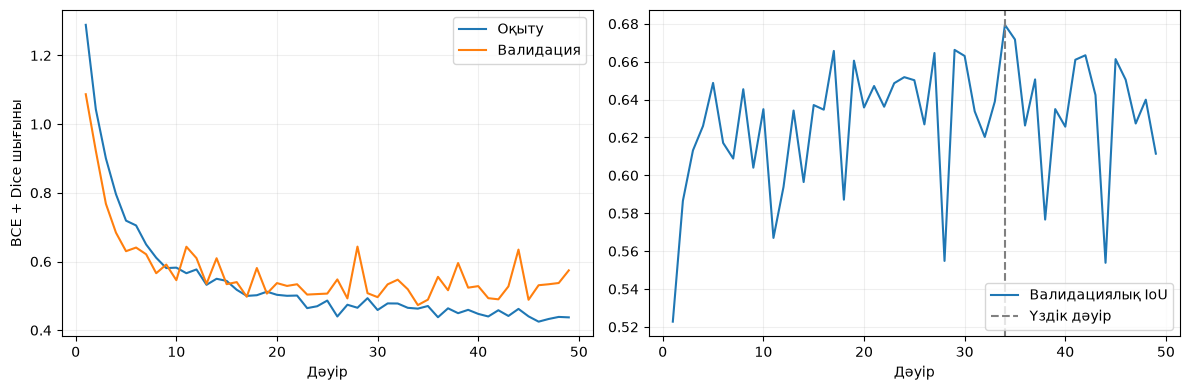

In [13]:
history = pd.read_csv(REPORT_DIR / "history.csv")
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.epoch, history.train_loss, label="Оқыту")
axes[0].plot(history.epoch, history.valid_loss, label="Валидация")
axes[0].set_ylabel("BCE + Dice шығыны")
axes[1].plot(history.epoch, history.valid_iou, label="Валидациялық IoU")
axes[1].axvline(bundle["epoch"], linestyle="--", color="gray", label="Үздік дәуір")
for axis in axes:
    axis.set_xlabel("Дәуір")
    axis.legend()
    axis.grid(alpha=0.2)
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "learning_curves.png", dpi=180)
plt.show()

### 5.1 Шекті валидация арқылы бекіту
Базалық ResNet-34 U-Net үшін шек — 0,5. Attention нұсқасына сол базалық модельдің валидациялық Recall көрсеткішіне ең жақын толықтықты беретін шек таңдалды. Бұл жалған оң болжамдарды салыстырмалы толықтықта салыстыруға мүмкіндік береді. Таңдалған шек — 0,473. Тестте бұл шек қайта реттелмейді.

Базалық Recall: 0.8038957406891161
Attention Recall: 0.8039006707583253


,Мәні
threshold,0.473000
precision,0.814709
recall,0.803901
iou,0.679640


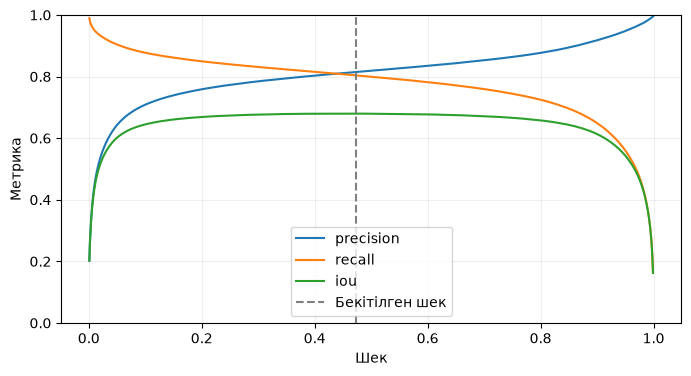

In [14]:
validation = pd.read_csv(REPORT_DIR / "validation.csv")
baseline_validation = pd.read_csv(REPORT_DIR / "baseline_validation.csv")
baseline_point = baseline_validation.loc[
    np.isclose(baseline_validation.threshold, 0.5)
].iloc[0]
selected = validation.loc[np.isclose(validation.threshold, threshold)].iloc[0]
closest_difference = (validation.recall - baseline_point.recall).abs().min()
assert abs(selected.recall - baseline_point.recall) <= closest_difference + 1e-12
print("Базалық Recall:", baseline_point.recall)
print("Attention Recall:", selected.recall)
display(selected[["threshold", "precision", "recall", "iou"]].to_frame("Мәні"))
figure, axis = plt.subplots(figsize=(8, 4))
for metric in ["precision", "recall", "iou"]:
    axis.plot(validation.threshold, validation[metric], label=metric)
axis.axvline(threshold, color="gray", linestyle="--", label="Бекітілген шек")
axis.set(xlabel="Шек", ylabel="Метрика", ylim=(0, 1))
axis.legend()
axis.grid(alpha=0.2)
plt.show()

## 6. Базалық шешім және салыстыру нәтижелері
Otsu VH арнасының гистограммасынан автоматты шек анықтайды. Нейрондық желілермен салыстыруда бірдей жарамды эталон пиксельдері пайдаланылады. Төмендегі кесте бұрын аяқталған тәжірибелердің сақталған нәтижелерінен оқылады. Жаңа толық бағалау 7.3 бөлімінде қосылады.

In [15]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import rasterio
from rasterio.warp import reproject, Resampling


@torch.inference_mode()
def predict(model, x, valid, norm, device):
    z = normalize(x, valid, norm)
    patches = []
    for top in [0, 256]:
        for left in [0, 256]:
            a = torch.from_numpy(z[:, top : top + 256, left : left + 256].copy())[
                None
            ].to(device)
            patches.append(model(a).sigmoid()[0, 0].cpu().numpy())
    return assemble(patches)


def otsu(x, valid):
    from skimage.filters import threshold_otsu

    values = x[1][valid]
    if not len(values) or np.ptp(values) == 0:
        return np.zeros_like(valid)
    return x[1] < threshold_otsu(values)


def export_raster(source, path, array, valid, probability=False):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    nodata = -9999 if probability else 255
    dtype = "float32" if probability else "uint8"
    with rasterio.open(source) as ds:
        profile = ds.profile.copy()
    profile.update(count=1, dtype=dtype, nodata=nodata, compress="deflate")
    with rasterio.open(path, "w", **profile) as dst:
        dst.write(np.where(valid, array, nodata).astype(dtype), 1)

In [16]:
comparison = pd.read_csv(REPORT_DIR / "comparison.csv")
main_result = json.loads((REPORT_DIR / "attention_main_test.json").read_text())
matched_result = json.loads((REPORT_DIR / "results.json").read_text())
attention_rows = pd.DataFrame(
    [
        {"model": "attention_resnet34", "split": "test", **main_result},
        {
            "model": "attention_resnet34",
            "split": "bolivia",
            **matched_result["bolivia"]["attention"],
        },
    ]
)
comparison = comparison[comparison.model != "attention_resnet34"]
comparison = pd.concat([comparison, attention_rows], ignore_index=True)
metric_columns = ["iou", "f1", "precision", "recall"]
for column in metric_columns:
    comparison[column] = pd.to_numeric(
        comparison[column].astype(str).str.replace(",", ".", regex=False),
        errors="raise",
    )
display(
    comparison[["model", "split"] + metric_columns].style.format(
        {key: "{:.4f}" for key in metric_columns}
    )
)
print("Негізгі тест көлемі:", main_result["tiles"])

,model,split,iou,f1,precision,recall
0,otsu,bolivia,0.4044,0.5759,0.4322,0.8628
1,otsu,test,0.2314,0.3758,0.2532,0.7288
2,plain,bolivia,0.5895,0.7417,0.8335,0.6681
3,plain,test,0.6682,0.8011,0.8174,0.7855
4,resnet34,bolivia,0.6852,0.8132,0.7785,0.8511
5,resnet34,test,0.6846,0.8128,0.8077,0.8178
6,resnet34_scratch,bolivia,0.6354,0.7771,0.8928,0.6879
7,resnet34_scratch,test,0.6822,0.8111,0.8331,0.7902
8,attention_resnet34,test,0.6886,0.8156,0.8184,0.8129
9,attention_resnet34,bolivia,0.6955,0.8204,0.7901,0.8531


Негізгі тест көлемі: 90


## 7. Дайын модельдің суреттегі болжамы
Әр 512 × 512 сурет төрт 256 × 256 патчқа бөлінеді. Патч ықтималдықтары бастапқы торға қайта жиналады. Ықтималдық ≥ 0,473 болған пиксель су деп белгіленеді.

Екі Боливия фрагменті демонстрация үшін алдын ала белгіленген. Бұл екі фрагмент бойынша есеп толық 90 суреттік тесттен бөлек көрсетіледі. Қате картасында жасыл — дұрыс табылған су, қызыл — құрлықты су деп тану (FP), көк — өткізіп алынған су (FN), сұр — эталон белгісіз.

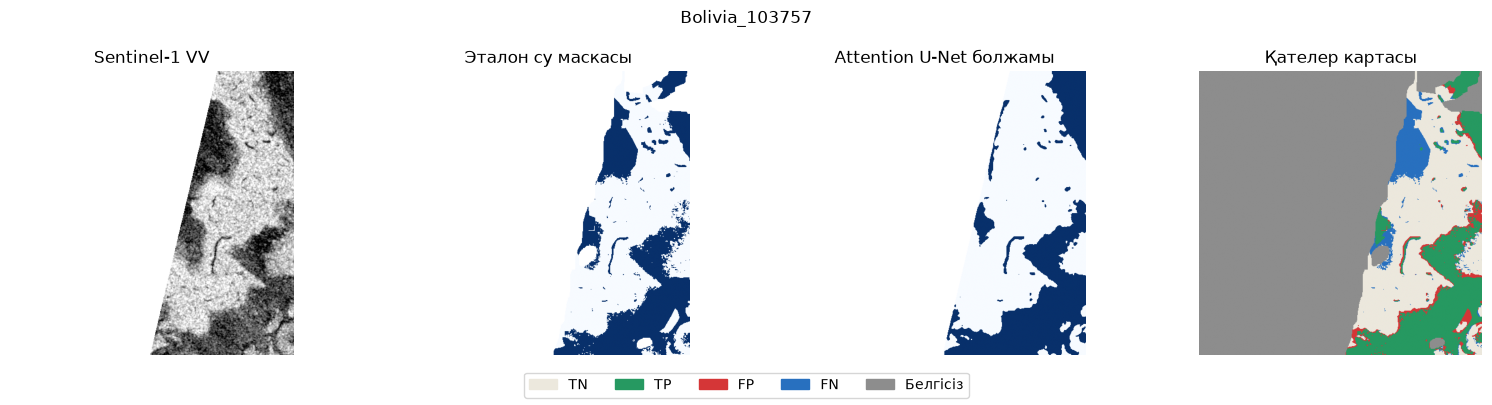

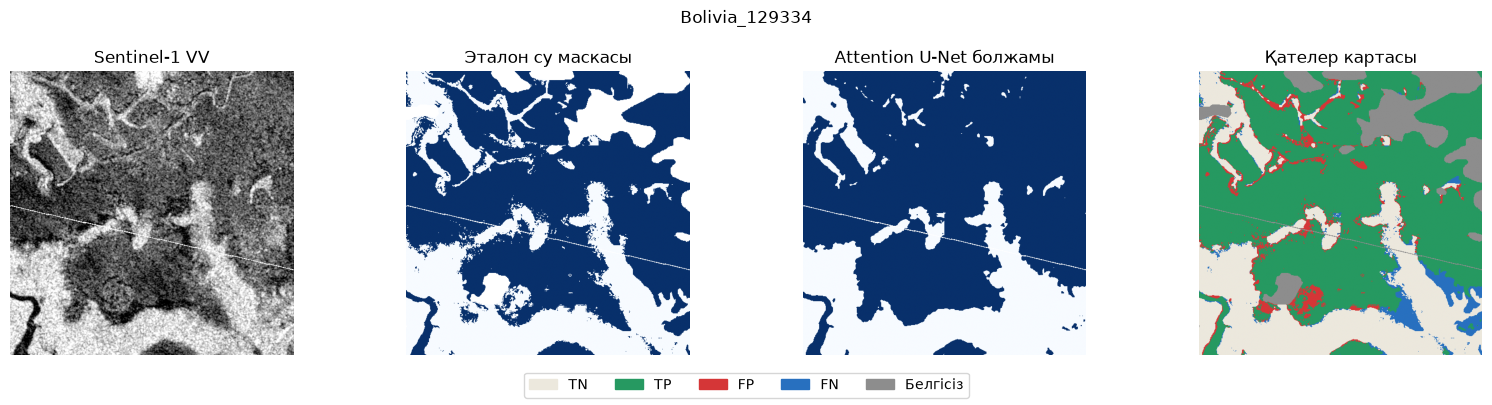

Осы іске қосудағы екі Боливия фрагменті


,Attention U-Net,Otsu
iou,0.832149,0.839694
f1,0.908386,0.912863
precision,0.911809,0.942938
recall,0.904988,0.884647
tp,173241.000000,169347.000000
fp,16756.000000,10248.000000
fn,18188.000000,22082.000000
tn,116957.000000,123465.000000


In [17]:
demo_ids = ["Bolivia_103757", "Bolivia_129334"]
demo_rows = manifest[manifest.chip_id.isin(demo_ids)]
assert len(demo_rows) == 2
# Демонстрация суреттері жоқ болса, ресми Sen1Floods11 көзінен жүктеледі.
for demo_row in demo_rows.to_dict("records"):
    for key, folder in [("image", "S1Hand"), ("label", "LabelHand")]:
        demo_path = Path(demo_row[key])
        download(BASE + HAND + folder + "/" + demo_path.name, demo_path)
demo_counts = np.zeros(4, dtype=np.int64)
otsu_counts = np.zeros(4, dtype=np.int64)
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

for row in demo_rows.to_dict("records"):
    image, target, label_valid = read_pair(row)
    _, image_valid = read_image(row)
    probability = predict(model, image, image_valid, normalization, DEVICE)
    predicted_water = probability >= threshold
    demo_counts += counts(predicted_water, target, label_valid)
    otsu_counts += counts(otsu(image, image_valid), target, label_valid)
    errors = np.zeros(target.shape, dtype="uint8")
    errors[label_valid & predicted_water & (target == 1)] = 1
    errors[label_valid & predicted_water & (target == 0)] = 2
    errors[label_valid & ~predicted_water & (target == 1)] = 3
    errors[~label_valid] = 4
    figure, axes = plt.subplots(1, 4, figsize=(16, 4))
    low, high = np.percentile(image[0][image_valid], [2, 98])
    axes[0].imshow(image[0], cmap="gray", vmin=low, vmax=high)
    axes[0].set_title("Sentinel-1 VV")
    axes[1].imshow(np.where(label_valid, target, np.nan), cmap="Blues", vmin=0, vmax=1)
    axes[1].set_title("Эталон су маскасы")
    axes[2].imshow(
        np.where(image_valid, predicted_water, np.nan), cmap="Blues", vmin=0, vmax=1
    )
    axes[2].set_title("Attention U-Net болжамы")
    colors = ["#ece8dd", "#269961", "#d53637", "#2870bf", "#8d8d8d"]
    axes[3].imshow(errors, cmap=ListedColormap(colors), vmin=0, vmax=4)
    axes[3].set_title("Қателер картасы")
    for axis in axes:
        axis.axis("off")
    figure.suptitle(row["chip_id"])
    figure.legend(
        handles=[
            Patch(color=color, label=label)
            for color, label in zip(colors, ["TN", "TP", "FP", "FN", "Белгісіз"])
        ],
        loc="lower center",
        ncol=5,
    )
    figure.tight_layout(rect=[0, 0.08, 1, 0.95])
    figure.savefig(OUTPUT_DIR / (row["chip_id"] + ".png"), dpi=180)
    plt.show()
    export_raster(
        row["image"],
        OUTPUT_DIR / (row["chip_id"] + "_water.tif"),
        predicted_water,
        image_valid,
    )
    export_raster(
        row["image"],
        OUTPUT_DIR / (row["chip_id"] + "_probability.tif"),
        probability,
        image_valid,
        True,
    )

print("Осы іске қосудағы екі Боливия фрагменті")
display(
    pd.DataFrame(
        {"Attention U-Net": metrics(demo_counts), "Otsu": metrics(otsu_counts)}
    )
)
write_json(
    OUTPUT_DIR / "demo_metrics.json",
    {
        "chips": demo_ids,
        "attention": metrics(demo_counts),
        "otsu": metrics(otsu_counts),
    },
)

### 7.3 Толық тестті қайта есептеу
`RUN_FULL_TEST=True` кезінде ресми test және Bolivia бөліктерінің файлдары жүктеліп, дайын модельдің метрикалары қайта есептеледі. Нормализация мен 0,473 шегі өзгермейді. Нәтиже `outputs/recomputed_metrics.json` файлына жазылады. Әртүрлі PyTorch және CPU/GPU нұсқаларында шекке өте жақын пиксельдерде аздаған сандық айырма болуы мүмкін.

In [18]:
if RUN_FULL_TEST:
    full_records = []
    for row in manifest[manifest.split.isin(["test", "bolivia"])].to_dict("records"):
        for key, folder in [("image", "S1Hand"), ("label", "LabelHand")]:
            path = Path(row[key])
            download(BASE + HAND + folder + "/" + path.name, path)
        image, target, valid = read_pair(row)
        _, image_valid = read_image(row)
        probability = predict(model, image, image_valid, normalization, DEVICE)
        full_records.append(
            {
                "chip_id": row["chip_id"],
                "split": row["split"],
                **metrics(counts(probability >= threshold, target, valid)),
            }
        )
        if len(full_records) % 10 == 0:
            print("Бағаланды:", len(full_records))
    full_table = pd.DataFrame(full_records)
    full_table.to_csv(OUTPUT_DIR / "recomputed_per_tile.csv", index=False)
    recalculated = {
        split: metrics(group[["tp", "fp", "fn", "tn"]].sum().to_numpy())
        for split, group in full_table.groupby("split")
    }
    write_json(OUTPUT_DIR / "recomputed_metrics.json", recalculated)
    display(pd.DataFrame(recalculated))
else:
    print("Толық тесттің сақталған нәтижесі 6-бөлімде көрсетілді.")

Толық тесттің сақталған нәтижесі 6-бөлімде көрсетілді.


## 8. Дайын модельді joblib арқылы экспорттау
Экспорт салмақтарды CPU-дағы NumPy массивтеріне түрлендіреді. Пакетке модель конфигурациясы, екі арнаның нормализациясы, шешім шегі, таңдалған дәуір, дерек бөлінуі және бастапқы салмақ файлының SHA-256 хэші кіреді. Нәтиже — `outputs/attention_unet_resnet34_export.joblib`.

Қайта жүктеуден кейін модель сол суретке қайта болжам жасайды. Ықтималдықтар мен екілік маскалардың сәйкестігі тексеріледі. Архитектураны құратын код осы ноутбукте және `inference.py` файлында берілген.

In [19]:
export_path = OUTPUT_DIR / "attention_unet_resnet34_export.joblib"
export_bundle = dict(bundle)
export_bundle["state_dict"] = {
    name: value.detach().cpu().numpy().copy()
    for name, value in model.state_dict().items()
}
export_bundle["export_environment"] = {
    name: importlib.metadata.version(name)
    for name in ["torch", "segmentation-models-pytorch", "numpy", "joblib"]
}
temporary_path = export_path.with_suffix(".joblib.tmp")
joblib.dump(export_bundle, temporary_path, compress=3)
temporary_path.replace(export_path)

restored_bundle = joblib.load(export_path)
restored_model = build_model(restored_bundle["config"]["model"], pretrained=False)
restored_model.load_state_dict(
    {
        name: torch.from_numpy(value.copy())
        for name, value in restored_bundle["state_dict"].items()
    },
    strict=True,
)
restored_model.to(DEVICE).eval()
check_row = demo_rows.iloc[0].to_dict()
check_image, check_valid = read_image(check_row)
original_probability = predict(model, check_image, check_valid, normalization, DEVICE)
restored_probability = predict(
    restored_model, check_image, check_valid, restored_bundle["normalization"], DEVICE
)
np.testing.assert_allclose(
    original_probability, restored_probability, rtol=0, atol=1e-7
)
assert np.array_equal(
    original_probability >= threshold,
    restored_probability >= restored_bundle["threshold"],
)
verification = {
    "max_probability_difference": float(
        np.max(np.abs(original_probability - restored_probability))
    ),
    "identical_masks": True,
    "chip_id": check_row["chip_id"],
    "file_sha256": hashlib.sha256(export_path.read_bytes()).hexdigest(),
}
write_json(OUTPUT_DIR / "export_verification.json", verification)
print("Экспорт дайын:", export_path)
print("Көлемі, МБ:", round(export_path.stat().st_size / 1e6, 2))
print("Болжамдардың ең үлкен айырмасы:", verification["max_probability_difference"])
print("Екілік маскалар толық сәйкес келеді.")

Экспорт дайын: .../FloodSegmentation_Defense\outputs\attention_unet_resnet34_export.joblib
Көлемі, МБ: 91.46
Болжамдардың ең үлкен айырмасы: 0.0
Екілік маскалар толық сәйкес келеді.


## Қорытынды және қолдану шектеулері
Негізгі 90 фрагменттік тестте Attention U-Net IoU 0,6886, Dice/F1 0,8156, Precision 0,8184 және Recall 0,8129 көрсетті. Боливияда салыстырмалы толықтық кезінде жалған оң пиксельдер саны 109 443-тен 102 390-ға азайды. Бұл өзгеріс барлық суретте бірдей емес, сондықтан жеке қате карталары да талданады.

Жұмыс сенсорлық су маскаларын дайындауға, геоақпараттық талдауға және тасқын мониторингіне бастапқы карта ұсынуға арналған. Қазақстан аумағында қолдану үшін жергілікті таңбаланған деректерде бағалау қажет. Бір seed пен бір географиялық holdout нәтижесі барлық өңірге жалпылау кепілдігін бермейді.

**Әдістердің көздері** — [Sen1Floods11](https://github.com/cloudtostreet/Sen1Floods11), [U-Net](https://arxiv.org/abs/1505.04597), [ResNet](https://arxiv.org/abs/1512.03385), [Attention U-Net](https://arxiv.org/abs/1804.03999), [Segmentation Models PyTorch](https://github.com/qubvel-org/segmentation_models.pytorch).